# 03 · Part 3: scaling

**Question.** On SIFT, how does the cost of reaching recall 0.95 grow with the number of base vectors N, for exact search, IVF-Flat and HNSW? The hypothesis is in `hypothesis.md`, committed before this notebook first ran. The next cell refuses to continue unless that commit exists.

**Setup.** The base set is the first N SIFT vectors, at three sizes; the queries and the query halves stay the same, and ground truth is recomputed for each N. One thing changes at a time: N. HNSW keeps M = 16 and efConstruction = 200. IVF-Flat sets nlist = round(4√N), so the average list holds √N / 4 vectors. Each index is swept and its operating point at 0.95 chosen exactly as in Part 2. Choices are recorded in `design_note.md`.

In [1]:
%run ./00_core.ipynb

.

.

.

.

.

...

                                                                                         [100%]

.

.

                                                                                           [100%]

mode=full  results -> results  timing CPU 2  build threads 12


In [2]:
require_committed_hypothesis("Part 3")

Part 3 hypothesis committed in 52debec 2026-10-23 17:30:25 +0530


## Configurations

In [3]:
def scaling_configs(n, config=CONFIG):
    """(index kind, build settings, search values) for the two indexes at base size n."""
    nlist = scaling_nlist(n)
    return [("ivf_flat", dict(nlist=nlist), [p for p in config["nprobe"] if p <= nlist]),
            ("hnsw", dict(M=config["scaling_M"], efC=config["hnsw_efC"]), config["ef_search"])]


pd.DataFrame([dict(n_base=f"{n:,}", index=kind, build=json.dumps(params), search=f"{SEARCH_PARAM[kind]} up to {max(values)}")
              for n in CONFIG["scaling_sizes"] for kind, params, values in scaling_configs(n)])

,n_base,index,build,search
0,"100,000",ivf_flat,"{""nlist"": 1265}",nprobe up to 1024
1,"100,000",hnsw,"{""M"": 16, ""efC"": 200}",efSearch up to 2048
2,"300,000",ivf_flat,"{""nlist"": 2191}",nprobe up to 1024
3,"300,000",hnsw,"{""M"": 16, ""efC"": 200}",efSearch up to 2048
4,"1,000,000",ivf_flat,"{""nlist"": 4000}",nprobe up to 1024
5,"1,000,000",hnsw,"{""M"": 16, ""efC"": 200}",efSearch up to 2048


In [4]:
%%ipytest -qq

def test_full_mode_uses_the_assignment_sizes():
    assert FULL["scaling_sizes"] == [100_000, 300_000, 1_000_000]


@pytest.mark.parametrize("config", [FULL, QUICK], ids=["full", "quick"])
def test_only_nlist_changes_with_n(config):
    first, *rest = [scaling_configs(n, config) for n in config["scaling_sizes"]]
    for runs in rest:
        assert runs[1] == first[1]                                   # HNSW: identical at every size
        assert runs[0][1]["nlist"] > first[0][1]["nlist"]            # IVF-Flat: more lists as N grows
    for n in config["scaling_sizes"]:
        assert max(scaling_configs(n, config)[0][2]) <= scaling_nlist(n)

.

.

.

                                                                                          [100%]

## Run
SIFT is loaded once at the largest size; each smaller base set is its prefix. Each size's rows are written as soon as they are measured.

In [5]:
largest = load_dataset("sift", max(CONFIG["scaling_sizes"]))
for n in CONFIG["scaling_sizes"]:
    started = time.perf_counter()
    data = Dataset("sift", largest.base[:n], largest.queries, None, None)
    gt = ground_truth("sift", data.base, data.queries)
    rows = benchmark_exact(3, str(n), data, gt)
    for kind, params, values in scaling_configs(n):
        rows += benchmark_index(3, str(n), data, gt, kind, params, values)
    write_rows(rows, part=3, section=str(n))
    print(f"N={n:,}: {len(rows)} rows in {(time.perf_counter() - started) / 60:.1f} min")
del largest, data, gt

100000  ivf_flat {'nlist': 1265}: built in 1.5 s, best tune recall 0.996


100000  hnsw {'M': 16, 'efC': 200}: built in 2.4 s, best tune recall 0.996
N=100,000: 41 rows in 0.8 min


300000  ivf_flat {'nlist': 2191}: built in 7.4 s, best tune recall 0.996


300000  hnsw {'M': 16, 'efC': 200}: built in 11.4 s, best tune recall 0.995
N=300,000: 45 rows in 2.0 min


1000000  ivf_flat {'nlist': 4000}: built in 48.7 s, best tune recall 0.998


1000000  hnsw {'M': 16, 'efC': 200}: built in 51.6 s, best tune recall 0.996
N=1,000,000: 49 rows in 5.7 min


## Cost of recall 0.95 against N
Left: report-half latency at each index's operating point for recall 0.95. Right: distance computations per query at the same points, which is the work behind the latency. Both axes are logarithmic, so a power law N^b is a straight line of slope b. The label at each line's end is its fitted slope: about 1 means the cost grows like N, 0.5 like √N, and close to 0 like log N.

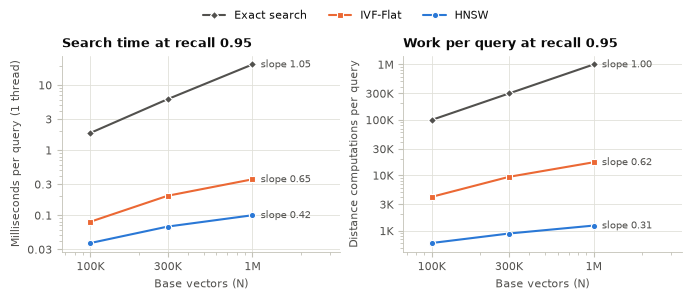

In [6]:
results = read_results()
figure, tables = part3_assets(results)
plt.show()

## Tables
- **Cost at each size:** the setting chosen for 0.95 on the tune half, with its report-half recall, QPS, latency, distance computations, build time and bytes per vector.
- **Growth:** fitted slopes for latency and for distance computations, how much each grew over the measured range, and the Q4 inputs. Latency at 150K comes from the fit inside the measured range; latency at 10M extrapolates it 10× beyond the largest size. Memory is bytes per vector at the largest size × N.

In [7]:
for name, table in tables.items():
    print(name)
    display(table)

part3_scaling


,N,Method,Setting for 0.95,Recall,QPS,ms/query,Distances/query,Build (s),Bytes/vector
0,"100,000",Exact search,full scan,1.000,542,1.845,"100,000",0.0,512
1,"100,000",IVF-Flat,"nlist=1265, nprobe=32",0.958,"12,524",0.080,"4,103",1.5,527
2,"100,000",HNSW,"M=16, efSearch=32",0.958,"26,598",0.038,604,2.4,656
3,"300,000",Exact search,full scan,1.000,164,6.088,"300,000",0.0,512
4,"300,000",IVF-Flat,"nlist=2191, nprobe=48",0.970,"5,001",0.200,"9,416",7.4,524
5,"300,000",HNSW,"M=16, efSearch=48",0.966,"14,872",0.067,895,11.4,656
6,"1,000,000",Exact search,full scan,1.000,48.2,20.737,"1,000,000",0.1,512
7,"1,000,000",IVF-Flat,"nlist=4000, nprobe=48",0.962,"2,798",0.357,"17,246",48.7,522
8,"1,000,000",HNSW,"M=16, efSearch=64",0.971,"9,966",0.100,"1,245",51.6,656


part3_growth


,Method,Slope: ms,Slope: dist.,N grows,ms grows,ms at 150K,GB at 150K,ms at 10M,GB at 10M
0,Exact search,1.05,1.00,10x,11.2x,2.86,0.08,235.78,5.12
1,IVF-Flat,0.65,0.62,10x,4.5x,0.11,0.08,1.70,5.22
2,HNSW,0.42,0.31,10x,2.7x,0.05,0.10,0.28,6.56


In [8]:
%%ipytest -qq

scaling = scaling_table(results)


def test_every_size_has_all_three_methods():
    methods = scaling.groupby("n_base")["index"].agg(set)
    assert all(found == {"exact", "ivf_flat", "hnsw"} for found in methods)
    assert sorted(scaling["n_base"].unique()) == CONFIG["scaling_sizes"]


def test_both_indexes_reach_095_at_every_size():
    assert (scaling["setting"] != "not reached").all()


def test_exact_search_computes_every_distance():
    exact = scaling[scaling["index"] == "exact"]
    assert (exact["distances_per_query"] == exact["n_base"]).all()

.

.

.

                                                                                          [100%]